# Outcome Success Measurement — OSA_STORE_ACTIONABLE & OSA_BIG_DROP

Experimental notebook (DS/build team). Measures the real £ impact of alerts that
a store manager interacted with in the app (`ALERT_ACTION_STATUS`, latest row
per `ACTION_ID`). The **primary cohort** is `status='completed' AND
outcome='completed'` (74 rows); the review dataset additionally keeps
`completed/partial`, `completed/couldnt_complete` and `in-progress` rows as
**analysis-only** cohorts — they are excluded from all headline totals.

- **OSA_STORE_ACTIONABLE** — `impact_gbp = (OSA_after − OSA_before) × (Σ ACTUAL_SALES_VALUE + Σ LOST_SALES_VALUE)_after_week`
  - Baseline **A** (headline): the card's own problem-week OSA from `SIGNAL_JSON`.
  - Baseline **B** (secondary): recomputed OSA over the 7 days before Completion.
  - After-week: `[anchor+1, anchor+7]` where anchor = `UPDATED_AT::date` for
    completed rows and `ANALYSIS_DATE` (card date) for `in-progress` rows —
    in-progress has no action timestamp, so the window measures post-*card*
    behaviour, not post-*action*.
- **OSA_BIG_DROP** — compares the drop day (`SIGNAL_JSON:latest_date`) against:
  - **A:** same weekday next week (`latest_date + 7`), and
  - **B:** first same weekday on/after `anchor+1`.
  - Per compare day: `lsv_recovered_gbp` and `impact_gbp = ΔOSA × (sales £ + LSV £)`.

All computation runs in Snowpark; `ACTUAL_SALES_VALUE` is read from the raw OSA
fact `ANALYSIS.FINAL.LSM_ITEM_STORE_DAY_REPORTING_PERIOD` (not on `OSA_V1`).

Measurement statuses: **measured** (after-window fully available), **evaluating**
(after-window not yet mature), **no_data** (window mature but zero rows —
possible range change / outage, not treated as £0).

The unified per-action frame (`res_review`) can be published to
`STORE_INSIGHT_DEV.PUBLIC.RECENT_SUCCESSES_REVIEW` by setting
`WRITE_REVIEW_TABLE = True` (see last section).

<!-- TODO(glossary): add "Workflow Outcome" (app-side ALERT_ACTION_STATUS.OUTCOME,
distinct from the pipeline Outcome concept) and "Measurement Status"
(measured/evaluating/no_data) to pipeline/CONTEXT.md -->


In [43]:
# --- Parameters ------------------------------------------------------------
CLIENT          = 'eastofengland'
DB              = 'STORE_INSIGHT_DB'          # CRT
SCHEMA          = 'PUBLIC'
RAW_OSA_TABLE   = 'ANALYSIS.FINAL.LSM_ITEM_STORE_DAY_REPORTING_PERIOD'
SIGNAL_TYPES    = ('OSA_STORE_ACTIONABLE', 'OSA_BIG_DROP')
STORE_IDS       = None                       # e.g. [204, 239] to restrict
RUN_DATE_FROM   = None                       # e.g. '2026-10-02'
EXPORT_CSV      = None                       # e.g. 'outcomes_export.csv' (gitignore before use)
WRITE_REVIEW_TABLE = True                    # set True to (re)publish the review table — table does not exist until first run with True

ALERTS_TABLE        = f'{DB}.{SCHEMA}.ALERTS_PIPELINE'
ACTION_STATUS_TABLE = f'{DB}.{SCHEMA}.ALERT_ACTION_STATUS'

print(f'Alerts        : {ALERTS_TABLE}')
print(f'Action status : {ACTION_STATUS_TABLE}')
print(f'OSA fact      : {RAW_OSA_TABLE}')

Alerts        : STORE_INSIGHT_DB.PUBLIC.ALERTS_PIPELINE
Action status : STORE_INSIGHT_DB.PUBLIC.ALERT_ACTION_STATUS
OSA fact      : ANALYSIS.FINAL.LSM_ITEM_STORE_DAY_REPORTING_PERIOD


In [44]:
# --- Bootstrap -------------------------------------------------------------
import sys, os, logging, warnings
_root = os.path.abspath(os.path.join('..', '..', '..'))
if _root not in sys.path:
    sys.path.insert(0, _root)

logging.getLogger('snowflake.connector').setLevel(logging.ERROR)
logging.getLogger('snowflake.snowpark').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=UserWarning, module='snowflake')

from snowflake.snowpark import functions as F

from store_insight.pipeline.config.loader import load_config
from store_insight.pipeline.pipeline.session import create_session

cfg = load_config(CLIENT)
session = create_session(cfg)

print(f'Config loaded: client={cfg.client_name}')

 pip install snowflake-connector-python[secure-local-storage]


Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...
Going to open: https://login.microsoftonline.com/93a31d5d-1a5d-433f-baa0-138549cd2108/saml2?SAMLRequest=nZJfb9owFMW%2FSuQ9x4mT0IEFVBTUjamlrPyZ1DfjONTDsTNfpyn99HMCSN1D%2B7CXKLLPvb%2Fje%2B7w%2BrVUwYuwII0eIYJjFAjNTS71foQ269uwjwJwTOdMGS1G6CgAXY%2BHwEpV0UntnvWj%2BFMLcIFvpIG2FyNUW00NAwlUs1IAdZyuJvd3NMExZQDCOo9D55IcpGc9O1fRKGqaBjcpNnYfJXEcR%2FEg8qpW8gW9Q1SfMyprnOFGXUpe%2FZs%2BQJAozlqEV3jC8lx4I%2FVpBJ9RdicR0O%2Fr9TJcPqzWKJhcXjc1GupS2JWwL5KLzePdyQB4B1CSqzTOcH0IwfgZYvZWW4FBm6ZQ7CC4Kava%2BdbY%2F0WFyCNl9tIPbD4boeog88WBbH4z%2FrD9peD4bbObJl97uzdhquPNQfLtT9ZUC1b8eFrVnKNge4k3aeOdA9RirttQnT%2BKk6uQxCHJ1mRAs4xmPZz2%2Bk8omPlQpWauq7w473zgUnJrwBTOaCW16FwOUpaSvJeHhPlPlqZFuGPMN077vWzA84TE%2FaiNLkGn9aGdETv%2Br6EMo%2Fctzuu48AnNZ0ujJD8Gt8aWzH0cIMGkO5F5WHRSKkom1STPrQDwQSplmqkVzPmtd7

 pip install snowflake-connector-python[secure-local-storage]


Snowflake session created.
Config loaded: client=eastofengland


## 1. Matched alerts cohort — all workflow outcomes

Latest `ALERT_ACTION_STATUS` row per `ACTION_ID`, joined to `ALERTS_PIPELINE`
on `ALERT_ID`. Signal type is taken from `SIGNAL_JSON:signal_type` — `ALERT_TYPE`
only reliably equals signal type from 2 Oct onward, so both are used in the
filter. Earliest `RUN_DATE` per `ALERT_ID` gives the card the store first saw.

`alerts` keeps **every** matched workflow outcome. `WORKFLOW_STATUS` /
`WORKFLOW_OUTCOME` are normalised to lowercase; an empty outcome becomes NULL.
Headline totals re-filter to `completed/completed` in the Summary.

In [45]:
types_sql = ', '.join(f"'{t}'" for t in SIGNAL_TYPES)

extra_filters = ''
if STORE_IDS:
    extra_filters += f" AND a.STORE_ID IN ({', '.join(str(s) for s in STORE_IDS)})"
if RUN_DATE_FROM:
    extra_filters += f" AND a.RUN_DATE >= '{RUN_DATE_FROM}'"

cohort_sql = f"""
WITH wf AS (
    SELECT ACTION_ID, STATUS, OUTCOME, UPDATED_AT
    FROM {ACTION_STATUS_TABLE}
    QUALIFY ROW_NUMBER() OVER (PARTITION BY ACTION_ID ORDER BY UPDATED_AT DESC) = 1
),
matched AS (
    SELECT a.ALERT_ID, a.STORE_ID, a.SECTION, a.RUN_DATE, a.ANALYSIS_DATE,
           a.ALERT_TYPE, a.SIGNAL_JSON, a.FACTS_JSON,
           w.STATUS AS WF_STATUS, w.OUTCOME AS WF_OUTCOME, w.UPDATED_AT
    FROM wf w
    JOIN {ALERTS_TABLE} a ON a.ALERT_ID = w.ACTION_ID
    WHERE (PARSE_JSON(a.SIGNAL_JSON):signal_type::STRING IN ({types_sql})
           OR a.ALERT_TYPE IN ({types_sql}))
    {extra_filters}
),
first_card AS (
    SELECT *
    FROM matched
    QUALIFY ROW_NUMBER() OVER (PARTITION BY ALERT_ID ORDER BY RUN_DATE) = 1
)
SELECT * FROM first_card
"""

alerts_all = session.sql(cohort_sql).cache_result()

print('Workflow outcome mix among matched OSA cards (any status):')
alerts_all.group_by('WF_STATUS', 'WF_OUTCOME').count().sort('COUNT', ascending=False).show()

alerts = alerts_all.with_columns(
    ['WORKFLOW_STATUS', 'WORKFLOW_OUTCOME'],
    [
        F.lower(F.trim(F.col('WF_STATUS'))),
        F.when(F.trim(F.col('WF_OUTCOME')) == F.lit(''), F.lit(None))
         .otherwise(F.lower(F.trim(F.col('WF_OUTCOME')))),
    ],
).cache_result()

print(f'Full review cohort (all workflow outcomes): {alerts.count()}')

Workflow outcome mix among matched OSA cards (any status):
--------------------------------------------
|"WF_STATUS"  |"WF_OUTCOME"      |"COUNT"  |
--------------------------------------------
|Completed    |completed         |79       |
|Completed    |partial           |19       |
|in-progress  |                  |8        |
|Completed    |couldnt_complete  |4        |
--------------------------------------------

Full review cohort (all workflow outcomes): 110


In [46]:
# --- Parse JSON payloads + derive window columns (all Snowpark) ------------
sig   = F.parse_json(F.col('SIGNAL_JSON'))
facts = F.parse_json(F.col('FACTS_JSON'))

alerts = alerts.select(
    F.col('ALERT_ID'), F.col('STORE_ID'), F.col('SECTION'),
    F.to_date(F.col('RUN_DATE')).alias('RUN_DATE'),
    F.to_date(F.col('ANALYSIS_DATE')).alias('ANALYSIS_DATE'),
    F.col('ALERT_TYPE'),
    sig['signal_type'].cast('string').alias('SIGNAL_TYPE'),
    F.to_date(F.col('UPDATED_AT')).alias('COMPLETION_DATE'),
    F.col('WORKFLOW_STATUS'), F.col('WORKFLOW_OUTCOME'),
    # card-reported baselines
    sig['this_week_osa'].cast('float').alias('CARD_STORE_OSA_PCT'),
    sig['total_this_week_osa'].cast('float').alias('CARD_TOTAL_OSA_PCT'),
    sig['last_week_osa'].cast('float').alias('CARD_LAST_WEEK_OSA_PCT'),
    sig['this_week_lsv']['store_controlled'].cast('float').alias('CARD_LSV_STORE_GBP'),
    sig['this_week_lsv']['total'].cast('float').alias('CARD_LSV_TOTAL_GBP'),
    facts['cost_projection']['store_controlled_cost_of_inaction'].cast('float').alias('CARD_PROJ_COST_GBP'),
    # big-drop anchors
    F.to_date(sig['latest_date'].cast('string')).alias('DROP_DATE'),
    F.to_date(sig['prior_date'].cast('string')).alias('PRIOR_DATE'),
    sig['latest_day'].cast('string').alias('LATEST_DAY'),
    sig['prior_day'].cast('string').alias('PRIOR_DAY'),
).with_column(
    # window anchor: in-progress rows have no action timestamp, so anchor to
    # the card date; all other cohorts anchor to the workflow-change date
    'ANCHOR_DATE',
    F.when(F.col('WORKFLOW_STATUS') == 'in-progress', F.col('ANALYSIS_DATE'))
     .otherwise(F.col('COMPLETION_DATE')),
).with_columns(
    ['CARD_WEEK_START', 'B_BEFORE_START', 'B_BEFORE_END', 'AFTER_START', 'AFTER_END'],
    [
        F.dateadd('day', F.lit(-6), F.col('ANALYSIS_DATE')),
        F.dateadd('day', F.lit(-7), F.col('ANCHOR_DATE')),
        F.dateadd('day', F.lit(-1), F.col('ANCHOR_DATE')),
        F.dateadd('day', F.lit(1), F.col('ANCHOR_DATE')),
        F.dateadd('day', F.lit(7), F.col('ANCHOR_DATE')),
    ],
).with_column(
    'COMPARE_A', F.dateadd('day', F.lit(7), F.col('DROP_DATE')),
).with_column(
    # first same-weekday on/after anchor+1
    'COMPARE_B',
    F.dateadd(
        'day',
        F.call_function(
            'MOD',
            F.call_function('DAYOFWEEKISO', F.col('DROP_DATE'))
            - F.call_function('DAYOFWEEKISO', F.dateadd('day', F.lit(1), F.col('ANCHOR_DATE')))
            + F.lit(7),
            F.lit(7),
        ),
        F.dateadd('day', F.lit(1), F.col('ANCHOR_DATE')),
    ),
).cache_result()

alerts.select(
    'ALERT_ID', 'STORE_ID', 'SECTION', 'SIGNAL_TYPE', 'RUN_DATE', 'ANALYSIS_DATE',
    'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME', 'COMPLETION_DATE', 'ANCHOR_DATE',
    'CARD_STORE_OSA_PCT', 'CARD_LSV_STORE_GBP', 'DROP_DATE',
    'COMPARE_A', 'COMPARE_B',
).show(50)

----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"ALERT_ID"        |"STORE_ID"  |"SECTION"                  |"SIGNAL_TYPE"         |"RUN_DATE"  |"ANALYSIS_DATE"  |"WORKFLOW_STATUS"  |"WORKFLOW_OUTCOME"  |"COMPLETION_DATE"  |"ANCHOR_DATE"  |"CARD_STORE_OSA_PCT"  |"CARD_LSV_STORE_GBP"  |"DROP_DATE"  |"COMPARE_A"  |"COMPARE_B"  |
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|3a02d7861058a3af  |445         |EGGS                       |OSA_BIG_DROP          |2026-09-21  |2026-09-21       |completed          |partial             |2

## 2. Day-grain metrics from the raw OSA fact

One grouped aggregation at `(STORE_ID, ITEM_HIERARCHY_2, DATE)` covering the
full span of all alert windows. Store-controlled vs total attribution mirrors
`pipeline/pipeline/_shared.py::actionable_window_metrics`:
store-controlled rows are those with `INVENTORY_QTY > 0`.

In [47]:
# --- Window bounds + store filter for the daily pull -----------------------
bounds = alerts.select(
    F.least(
        F.min('CARD_WEEK_START'), F.min('B_BEFORE_START'),
        F.min(F.col('PRIOR_DATE')),
    ).alias('LO'),
    F.greatest(
        F.max('AFTER_END'), F.max('COMPARE_A'), F.max('COMPARE_B'),
    ).alias('HI'),
).collect()[0]
LO, HI = str(bounds['LO']), str(bounds['HI'])

store_ids = [r['STORE_ID'] for r in alerts.select('STORE_ID').distinct().collect()]

print(f'Daily metrics span : {LO} .. {HI}')
print(f'Stores             : {len(store_ids)}')

Daily metrics span : 2026-09-09 .. 2026-10-21
Stores             : 13


In [48]:
HIERARCHY_TABLE = cfg.tables.hierarchy

pos = F.col('INVENTORY_QTY') > 0

daily = (
    session.table(RAW_OSA_TABLE)
    .select(
        F.col('SITE_ID').alias('STORE_ID'),
        F.col('ITEM_ID').cast('string').alias('ITEM_CODE'),
        F.col('ANALYSIS_DATE').alias('DATE'),
        F.col('ACTUAL_SALES_VOLUME'),
        F.col('ACTUAL_SALES_VALUE'),
        F.col('LOST_SALES_VOLUME'),
        F.col('LOST_SALES_VALUE'),
        F.col('PERPETUAL_INVENTORY_QUANTITY').alias('INVENTORY_QTY'),
    )
    .filter(F.col('DATE') >= F.lit(LO))
    .filter(F.col('DATE') <= F.lit(HI))
    .filter(F.col('STORE_ID').isin(store_ids))
    .join(
        session.table(HIERARCHY_TABLE).select('ITEM_CODE', 'ITEM_HIERARCHY_2'),
        on='ITEM_CODE', how='left',
    )
    .filter(F.col('ITEM_HIERARCHY_2').is_not_null())
    .group_by('STORE_ID', 'ITEM_HIERARCHY_2', 'DATE')
    .agg(
        F.sum('ACTUAL_SALES_VOLUME').alias('SALES_VOL'),
        F.sum('ACTUAL_SALES_VALUE').alias('SALES_GBP'),
        F.sum('LOST_SALES_VOLUME').alias('LOST_VOL'),
        F.sum('LOST_SALES_VALUE').alias('LOST_GBP'),
        F.sum(F.when(pos, F.col('LOST_SALES_VOLUME')).otherwise(F.lit(0))).alias('STORE_LOST_VOL'),
        F.sum(F.when(pos, F.col('LOST_SALES_VALUE')).otherwise(F.lit(0))).alias('STORE_LOST_GBP'),
    )
    .cache_result()
)

latest_data_date = str(daily.select(F.max('DATE')).collect()[0][0]).split()[0]

print(f'Daily rows: {daily.count():,}   latest data date: {latest_data_date}')

Daily rows: 43,443   latest data date: 2026-10-13


## 3. Window aggregation + impact assembly

`window_metrics` joins alerts to the daily frame on
`(STORE_ID, SECTION = ITEM_HIERARCHY_2, DATE between window bounds)` and
aggregates per `ALERT_ID`. OSA mirrors the detector formulas:
`total_osa = sales_vol / (sales_vol + lost_vol)`,
`store_osa = sales_vol / (sales_vol + store_lost_vol)`.

In [49]:
def window_metrics(daily, alerts, start_col, end_col, prefix):
    """Aggregate daily metrics per alert over [alerts[start_col], alerts[end_col]]."""
    return (
        alerts.join(
            daily,
            (alerts['STORE_ID'] == daily['STORE_ID'])
            & (alerts['SECTION'] == daily['ITEM_HIERARCHY_2'])
            & (daily['DATE'] >= alerts[start_col])
            & (daily['DATE'] <= alerts[end_col]),
            how='inner',
        )
        .group_by(alerts['ALERT_ID'])
        .agg(
            F.count(daily['DATE']).alias(f'{prefix}_DAYS'),
            F.sum(daily['SALES_VOL']).alias(f'{prefix}_SALES_VOL'),
            F.sum(daily['SALES_GBP']).alias(f'{prefix}_SALES_GBP'),
            F.sum(daily['LOST_VOL']).alias(f'{prefix}_LOST_VOL'),
            F.sum(daily['LOST_GBP']).alias(f'{prefix}_LOST_GBP'),
            F.sum(daily['STORE_LOST_VOL']).alias(f'{prefix}_STORE_LOST_VOL'),
            F.sum(daily['STORE_LOST_GBP']).alias(f'{prefix}_STORE_LOST_GBP'),
        )
        .with_column(
            f'{prefix}_TOTAL_OSA',
            F.when(F.col(f'{prefix}_SALES_VOL') + F.col(f'{prefix}_LOST_VOL') != 0,
                   F.col(f'{prefix}_SALES_VOL')
                   / (F.col(f'{prefix}_SALES_VOL') + F.col(f'{prefix}_LOST_VOL')))
            .otherwise(0),
        )
        .with_column(
            f'{prefix}_STORE_OSA',
            F.when(F.col(f'{prefix}_SALES_VOL') + F.col(f'{prefix}_STORE_LOST_VOL') != 0,
                   F.col(f'{prefix}_SALES_VOL')
                   / (F.col(f'{prefix}_SALES_VOL') + F.col(f'{prefix}_STORE_LOST_VOL')))
            .otherwise(0),
        )
    )


def cohort_status(window_end_col, days_col):
    """measured / evaluating / no_data expression over window end + day count."""
    return (
        F.when(window_end_col > F.lit(latest_data_date), F.lit('evaluating'))
        .when(days_col.is_null() | (days_col == 0), F.lit('no_data'))
        .otherwise(F.lit('measured'))
    )

## 4. OSA_STORE_ACTIONABLE — before/after Completion

`impact_gbp = (OSA_after − OSA_before) × demand_gbp_after`

- `*_a`: baseline A — card-reported problem-week OSA (`CARD_*_OSA_PCT`).
- `*_b`: baseline B — recomputed OSA over `[completion−7, completion−1]`.
- `lsv_delta_gbp`: naive before/after LSV£ change (sanity column).

In [50]:
actionable = alerts.filter(F.col('SIGNAL_TYPE') == 'OSA_STORE_ACTIONABLE')

before_b = window_metrics(daily, actionable, 'B_BEFORE_START', 'B_BEFORE_END', 'BB')
after    = window_metrics(daily, actionable, 'AFTER_START', 'AFTER_END', 'A')

res_actionable = (
    actionable
    .join(before_b, on='ALERT_ID', how='left')
    .join(after, on='ALERT_ID', how='left')
    .with_columns(
        [
            'DELTA_STORE_OSA_A', 'DELTA_STORE_OSA_B',
            'DELTA_TOTAL_OSA_A', 'DELTA_TOTAL_OSA_B',
            'IMPACT_GBP_STORE_A', 'IMPACT_GBP_STORE_B',
            'IMPACT_GBP_TOTAL_A', 'IMPACT_GBP_TOTAL_B',
            'LSV_DELTA_GBP', 'STORE_LSV_DELTA_GBP', 'DAYS_CARD_TO_COMPLETION',
        ],
        [
            F.col('A_STORE_OSA') - F.col('CARD_STORE_OSA_PCT') / 100,
            F.col('A_STORE_OSA') - F.col('BB_STORE_OSA'),
            F.col('A_TOTAL_OSA') - F.col('CARD_TOTAL_OSA_PCT') / 100,
            F.col('A_TOTAL_OSA') - F.col('BB_TOTAL_OSA'),
            (F.col('A_STORE_OSA') - F.col('CARD_STORE_OSA_PCT') / 100)
            * (F.col('A_SALES_GBP') + F.col('A_LOST_GBP')),
            (F.col('A_STORE_OSA') - F.col('BB_STORE_OSA'))
            * (F.col('A_SALES_GBP') + F.col('A_LOST_GBP')),
            (F.col('A_TOTAL_OSA') - F.col('CARD_TOTAL_OSA_PCT') / 100)
            * (F.col('A_SALES_GBP') + F.col('A_LOST_GBP')),
            (F.col('A_TOTAL_OSA') - F.col('BB_TOTAL_OSA'))
            * (F.col('A_SALES_GBP') + F.col('A_LOST_GBP')),
            F.col('BB_LOST_GBP') - F.col('A_LOST_GBP'),
            F.col('BB_STORE_LOST_GBP') - F.col('A_STORE_LOST_GBP'),
            F.datediff('day', F.col('ANALYSIS_DATE'), F.col('COMPLETION_DATE')),
        ],
    )
    .with_column('COHORT_STATUS', cohort_status(F.col('AFTER_END'), F.col('A_DAYS')))
    .cache_result()
)

res_actionable.select(
    'ALERT_ID', 'STORE_ID', 'SECTION', 'ANALYSIS_DATE', 'COMPLETION_DATE',
    'COHORT_STATUS', 'DAYS_CARD_TO_COMPLETION',
    'CARD_STORE_OSA_PCT', 'BB_STORE_OSA', 'A_STORE_OSA',
    'IMPACT_GBP_STORE_A', 'IMPACT_GBP_STORE_B',
    'STORE_LSV_DELTA_GBP', 'CARD_PROJ_COST_GBP',
).show(50)

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"ALERT_ID"        |"STORE_ID"  |"SECTION"           |"ANALYSIS_DATE"  |"COMPLETION_DATE"  |"COHORT_STATUS"  |"DAYS_CARD_TO_COMPLETION"  |"CARD_STORE_OSA_PCT"  |"BB_STORE_OSA"  |"A_STORE_OSA"  |"IMPACT_GBP_STORE_A"  |"IMPACT_GBP_STORE_B"  |"STORE_LSV_DELTA_GBP"  |"CARD_PROJ_COST_GBP"  |
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|d7e9f39e00d5e3a1  |239         |BEER/LAGER & CIDER  |2026-09-26       |2026-09-27         |measured         |1                         

## 5. OSA_BIG_DROP — drop day vs same weekday

- `compare_a = drop_date + 7` (spec), `compare_b` = first same weekday ≥ completion+1.
- Per compare day: `lsv_recovered_gbp = LSV£_drop − LSV£_compare` and
  `impact_gbp = (OSA_compare − OSA_drop) × demand_gbp_compare`.
- `completed_after_compare_a` flags rows where the store finished after the
  spec compare day — recovery there can't be attributed to the action.

In [51]:
bigdrop = alerts.filter(F.col('SIGNAL_TYPE') == 'OSA_BIG_DROP')

drop = window_metrics(daily, bigdrop, 'DROP_DATE', 'DROP_DATE', 'D')
ca   = window_metrics(daily, bigdrop, 'COMPARE_A', 'COMPARE_A', 'CA')
cb   = window_metrics(daily, bigdrop, 'COMPARE_B', 'COMPARE_B', 'CB')

res_bigdrop = (
    bigdrop
    .join(drop, on='ALERT_ID', how='left')
    .join(ca, on='ALERT_ID', how='left')
    .join(cb, on='ALERT_ID', how='left')
    .with_columns(
        [
            'LSV_RECOVERED_GBP_A', 'LSV_RECOVERED_GBP_B',
            'DELTA_STORE_OSA_A', 'DELTA_STORE_OSA_B',
            'DELTA_TOTAL_OSA_A', 'DELTA_TOTAL_OSA_B',
        ],
        [
            F.col('D_STORE_LOST_GBP') - F.col('CA_STORE_LOST_GBP'),
            F.col('D_STORE_LOST_GBP') - F.col('CB_STORE_LOST_GBP'),
            F.col('CA_STORE_OSA') - F.col('D_STORE_OSA'),
            F.col('CB_STORE_OSA') - F.col('D_STORE_OSA'),
            F.col('CA_TOTAL_OSA') - F.col('D_TOTAL_OSA'),
            F.col('CB_TOTAL_OSA') - F.col('D_TOTAL_OSA'),
        ],
    )
    .with_columns(
        [
            'IMPACT_GBP_STORE_A', 'IMPACT_GBP_STORE_B',
            'IMPACT_GBP_TOTAL_A', 'IMPACT_GBP_TOTAL_B',
            'COMPLETED_AFTER_COMPARE_A', 'DAYS_DROP_TO_COMPLETION',
        ],
        [
            F.col('DELTA_STORE_OSA_A') * (F.col('CA_SALES_GBP') + F.col('CA_LOST_GBP')),
            F.col('DELTA_STORE_OSA_B') * (F.col('CB_SALES_GBP') + F.col('CB_LOST_GBP')),
            F.col('DELTA_TOTAL_OSA_A') * (F.col('CA_SALES_GBP') + F.col('CA_LOST_GBP')),
            F.col('DELTA_TOTAL_OSA_B') * (F.col('CB_SALES_GBP') + F.col('CB_LOST_GBP')),
            F.col('ANCHOR_DATE') > F.col('COMPARE_A'),
            F.datediff('day', F.col('DROP_DATE'), F.col('COMPLETION_DATE')),
        ],
    )
    .with_columns(
        ['STATUS_A', 'STATUS_B'],
        [
            cohort_status(F.col('COMPARE_A'), F.col('CA_DAYS')),
            cohort_status(F.col('COMPARE_B'), F.col('CB_DAYS')),
        ],
    )
    .cache_result()
)

res_bigdrop.select(
    'ALERT_ID', 'STORE_ID', 'SECTION', 'DROP_DATE', 'COMPLETION_DATE',
    'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME',
    'COMPARE_A', 'STATUS_A', 'COMPARE_B', 'STATUS_B',
    'COMPLETED_AFTER_COMPARE_A', 'DAYS_DROP_TO_COMPLETION',
    'LSV_RECOVERED_GBP_A', 'IMPACT_GBP_STORE_A',
    'LSV_RECOVERED_GBP_B', 'IMPACT_GBP_STORE_B',
).show(50)

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"ALERT_ID"        |"STORE_ID"  |"SECTION"                  |"DROP_DATE"  |"COMPLETION_DATE"  |"WORKFLOW_STATUS"  |"WORKFLOW_OUTCOME"  |"COMPARE_A"  |"STATUS_A"  |"COMPARE_B"  |"STATUS_B"  |"COMPLETED_AFTER_COMPARE_A"  |"DAYS_DROP_TO_COMPLETION"  |"LSV_RECOVERED_GBP_A"  |"IMPACT_GBP_STORE_A"  |"LSV_RECOVERED_GBP_B"  |"IMPACT_GBP_STORE_B"  |
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 6. Review dataset — all workflow cohorts

`res_review` is the unified per-action table: one row per matched OSA action
across all workflow cohorts, in a common column layout (`REVIEW_COLUMNS`).
Every row is kept — positive, zero, negative, evaluating and no_data.

Column notes:

- `COMPLETION_DATE` = `UPDATED_AT::date` (latest workflow timestamp). For
  in-progress rows it is the status-change date, not a completion; the windows
  are anchored to `ANALYSIS_DATE` for those rows (see `WORKFLOW_STATUS`).
- `MEASUREMENT_STATUS` = `measured` / `evaluating` / `no_data` window maturity.
- `BASELINE_A_OSA` = card-reported OSA; `BASELINE_B_OSA` = recomputed OSA
  (pre-anchor week for actionable, measured drop-day for big drop).
- Big-drop rows export the **A variant only**: `AFTER_*`/`COMPARE_DATE` are the
  `drop_date + 7` spec day; `BEFORE_*` = the drop day.
- `TOTAL_IMPACT_GBP` is the Baseline-A total-OSA impact (uses
  `CARD_TOTAL_OSA_PCT` for actionable rows); Baseline B has no exported total.
- `LSV_RECOVERED_GBP` = naive store-controlled LSV delta (actionable) or
  drop-day vs compare-day store-controlled LSV (big drop).
- `PROJECTED_COST_1WK_GBP` = `store_controlled_cost_of_inaction / 4`
  (actionable) or drop-day `this_week_lsv.store_controlled` (big drop).

In [52]:
from snowflake.snowpark.types import DateType, DoubleType

REVIEW_COLUMNS = [
    'ALERT_ID', 'STORE_ID', 'SIGNAL_TYPE', 'SECTION', 'CARD_RUN_DATE',
    'COMPLETION_DATE', 'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME', 'MEASUREMENT_STATUS',
    'BEFORE_START', 'BEFORE_END', 'BASELINE_A_OSA', 'BASELINE_B_OSA',
    'AFTER_START', 'AFTER_END', 'AFTER_OSA', 'AFTER_DEMAND_GBP',
    'MEASURED_IMPACT_GBP', 'TOTAL_IMPACT_GBP', 'LSV_RECOVERED_GBP',
    'PROJECTED_COST_1WK_GBP',
    'DROP_DATE', 'COMPARE_DATE', 'DROP_DAY_LSV', 'COMPARE_DAY_LSV',
]

rev_actionable = res_actionable.select(
    F.col('ALERT_ID'), F.col('STORE_ID'), F.col('SIGNAL_TYPE'), F.col('SECTION'),
    F.col('RUN_DATE').alias('CARD_RUN_DATE'),
    F.col('COMPLETION_DATE'),
    F.col('WORKFLOW_STATUS'), F.col('WORKFLOW_OUTCOME'),
    F.col('COHORT_STATUS').alias('MEASUREMENT_STATUS'),
    F.col('B_BEFORE_START').alias('BEFORE_START'),
    F.col('B_BEFORE_END').alias('BEFORE_END'),
    (F.col('CARD_STORE_OSA_PCT') / 100).cast(DoubleType()).alias('BASELINE_A_OSA'),
    F.col('BB_STORE_OSA').cast(DoubleType()).alias('BASELINE_B_OSA'),
    F.col('AFTER_START'), F.col('AFTER_END'),
    F.col('A_STORE_OSA').cast(DoubleType()).alias('AFTER_OSA'),
    (F.col('A_SALES_GBP') + F.col('A_LOST_GBP')).cast(DoubleType()).alias('AFTER_DEMAND_GBP'),
    F.col('IMPACT_GBP_STORE_A').cast(DoubleType()).alias('MEASURED_IMPACT_GBP'),
    F.col('IMPACT_GBP_TOTAL_A').cast(DoubleType()).alias('TOTAL_IMPACT_GBP'),
    F.col('STORE_LSV_DELTA_GBP').cast(DoubleType()).alias('LSV_RECOVERED_GBP'),
    (F.col('CARD_PROJ_COST_GBP') / 4).cast(DoubleType()).alias('PROJECTED_COST_1WK_GBP'),
    F.lit(None).cast(DateType()).alias('DROP_DATE'),
    F.lit(None).cast(DateType()).alias('COMPARE_DATE'),
    F.lit(None).cast(DoubleType()).alias('DROP_DAY_LSV'),
    F.lit(None).cast(DoubleType()).alias('COMPARE_DAY_LSV'),
)

rev_bigdrop = res_bigdrop.select(
    F.col('ALERT_ID'), F.col('STORE_ID'), F.col('SIGNAL_TYPE'), F.col('SECTION'),
    F.col('RUN_DATE').alias('CARD_RUN_DATE'),
    F.col('COMPLETION_DATE'),
    F.col('WORKFLOW_STATUS'), F.col('WORKFLOW_OUTCOME'),
    F.col('STATUS_A').alias('MEASUREMENT_STATUS'),
    F.col('DROP_DATE').alias('BEFORE_START'),
    F.col('DROP_DATE').alias('BEFORE_END'),
    (F.col('CARD_STORE_OSA_PCT') / 100).cast(DoubleType()).alias('BASELINE_A_OSA'),
    F.col('D_STORE_OSA').cast(DoubleType()).alias('BASELINE_B_OSA'),
    F.col('COMPARE_A').alias('AFTER_START'),
    F.col('COMPARE_A').alias('AFTER_END'),
    F.col('CA_STORE_OSA').cast(DoubleType()).alias('AFTER_OSA'),
    (F.col('CA_SALES_GBP') + F.col('CA_LOST_GBP')).cast(DoubleType()).alias('AFTER_DEMAND_GBP'),
    F.col('IMPACT_GBP_STORE_A').cast(DoubleType()).alias('MEASURED_IMPACT_GBP'),
    F.col('IMPACT_GBP_TOTAL_A').cast(DoubleType()).alias('TOTAL_IMPACT_GBP'),
    F.col('LSV_RECOVERED_GBP_A').cast(DoubleType()).alias('LSV_RECOVERED_GBP'),
    F.col('CARD_LSV_STORE_GBP').cast(DoubleType()).alias('PROJECTED_COST_1WK_GBP'),
    F.col('DROP_DATE'),
    F.col('COMPARE_A').alias('COMPARE_DATE'),
    F.col('D_STORE_LOST_GBP').cast(DoubleType()).alias('DROP_DAY_LSV'),
    F.col('CA_STORE_LOST_GBP').cast(DoubleType()).alias('COMPARE_DAY_LSV'),
)

res_review = (
    rev_actionable.union_by_name(rev_bigdrop)
    .select(*REVIEW_COLUMNS)
    .cache_result()
)

print(f'res_review rows: {res_review.count()}  (expected {alerts.count()})')
res_review.group_by(
    'SIGNAL_TYPE', 'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME', 'MEASUREMENT_STATUS'
).count().sort(
    'SIGNAL_TYPE', 'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME', 'MEASUREMENT_STATUS'
).show(50)

res_review rows: 110  (expected 110)
--------------------------------------------------------------------------------------------------
|"SIGNAL_TYPE"         |"WORKFLOW_STATUS"  |"WORKFLOW_OUTCOME"  |"MEASUREMENT_STATUS"  |"COUNT"  |
--------------------------------------------------------------------------------------------------
|OSA_BIG_DROP          |completed          |completed           |evaluating            |5        |
|OSA_BIG_DROP          |completed          |completed           |measured              |20       |
|OSA_BIG_DROP          |completed          |completed           |no_data               |1        |
|OSA_BIG_DROP          |completed          |couldnt_complete    |measured              |2        |
|OSA_BIG_DROP          |completed          |partial             |measured              |11       |
|OSA_BIG_DROP          |in-progress        |NULL                |evaluating            |2        |
|OSA_BIG_DROP          |in-progress        |NULL                |measure

## 7. Impact distributions

Box-and-whisker plots of measured £ impact, **measured rows only**
(`evaluating` rows have partial after-windows and would bias the distributions).
Two measures per cut: store-controlled `MEASURED_IMPACT_GBP` and
`TOTAL_IMPACT_GBP`. Cuts: signal type × baseline (A/B), workflow cohort, and
the top 8 sections by measured count. Each group is labelled with `n=` and its
median on the axis tick.

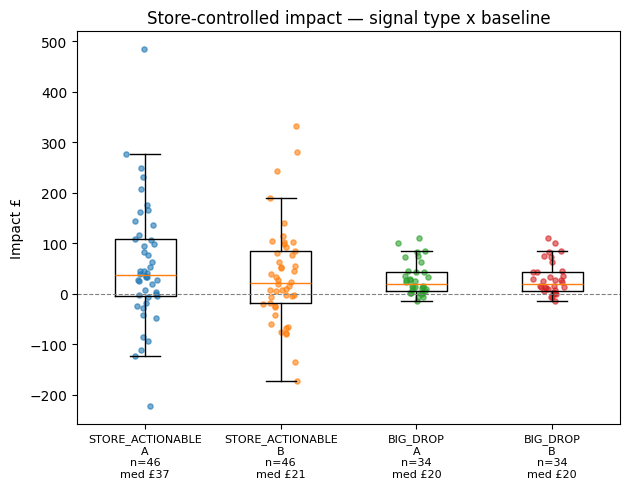

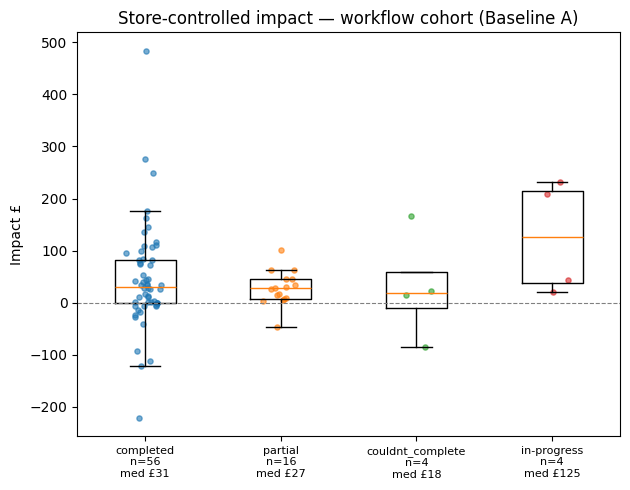

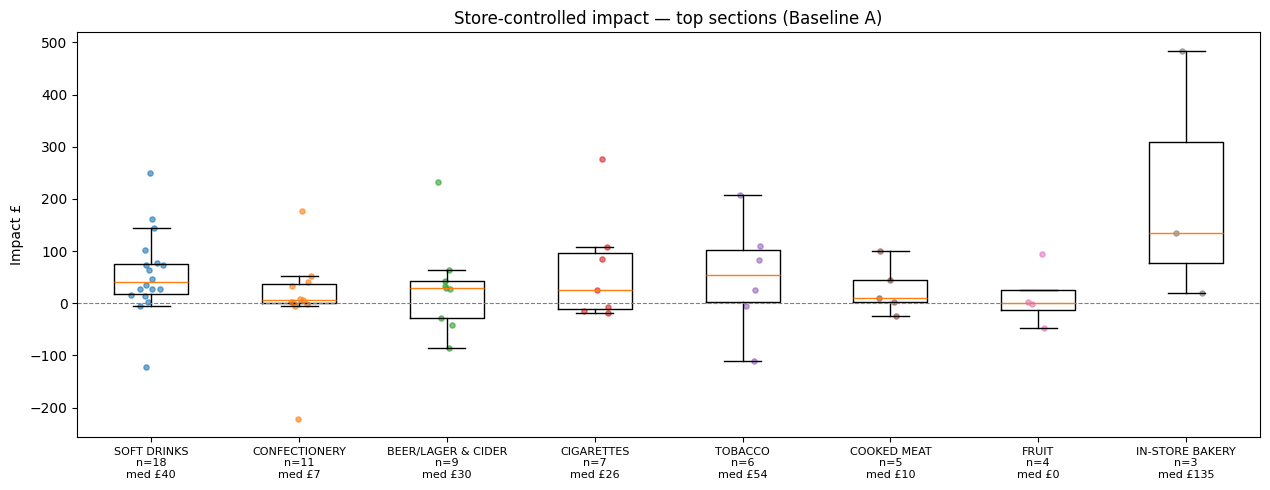

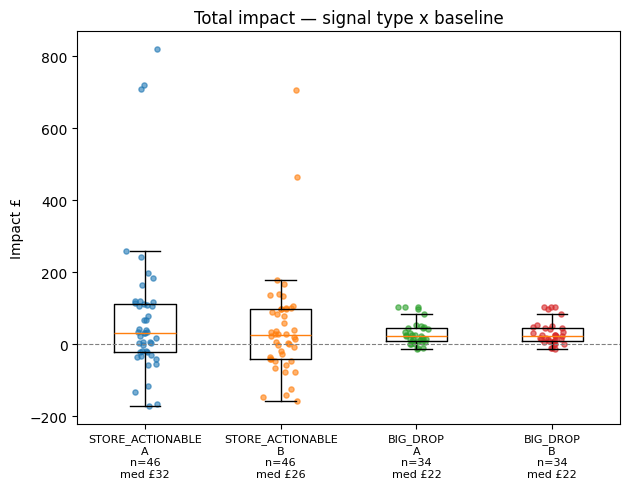

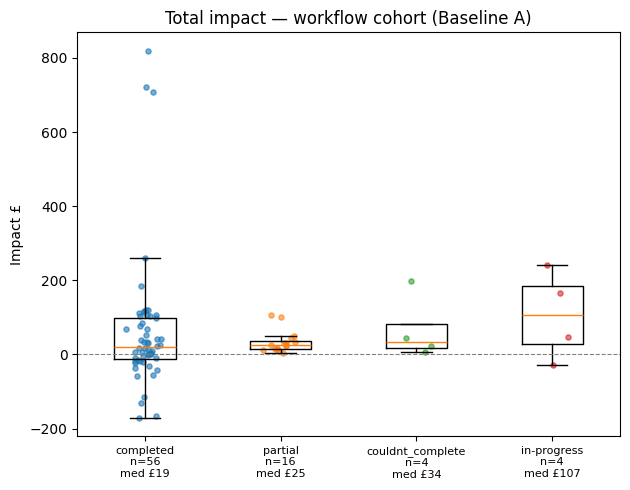

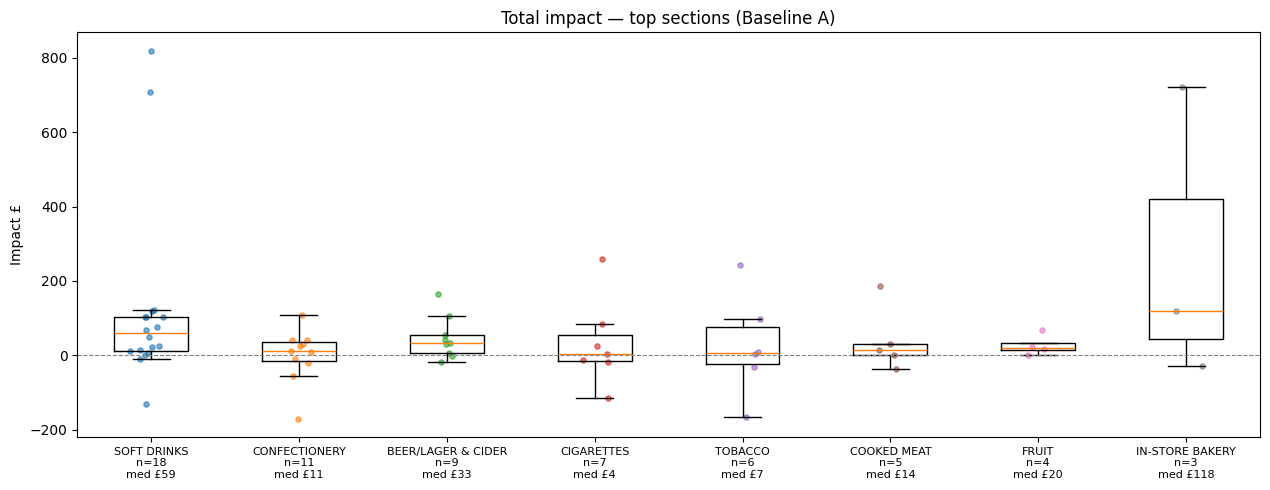

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pdf = res_review.to_pandas()
pdf_m = pdf[pdf['MEASUREMENT_STATUS'] == 'measured'].copy()
pdf_m['COHORT'] = pdf_m['WORKFLOW_OUTCOME'].fillna(pdf_m['WORKFLOW_STATUS'])

# A/B variants: B-side impact lives on res_actionable / res_bigdrop, not res_review
_AB_COLS = ['ALERT_ID', 'SIGNAL_TYPE',
            'IMPACT_GBP_STORE_A', 'IMPACT_GBP_STORE_B',
            'IMPACT_GBP_TOTAL_A', 'IMPACT_GBP_TOTAL_B']
pdf_ab = pd.concat([
    res_actionable.filter(F.col('COHORT_STATUS') == 'measured').select(*_AB_COLS).to_pandas(),
    res_bigdrop.filter(F.col('STATUS_A') == 'measured').select(*_AB_COLS).to_pandas(),
], ignore_index=True)


def _draw_box(pairs, title, ylabel='Impact £'):
    """pairs: list of (label, pandas Series). Empty groups are skipped."""
    pairs = [(l, s.dropna()) for l, s in pairs]
    pairs = [(l, s) for l, s in pairs if len(s)]
    if not pairs:
        print(f'(no measured data for {title})')
        return
    fig, ax = plt.subplots(figsize=(max(6, len(pairs) * 1.6), 5))
    ax.boxplot([s.values for _, s in pairs], showfliers=False)
    rng = np.random.default_rng(0)
    for i, (_, s) in enumerate(pairs, start=1):
        ax.scatter(rng.normal(i, 0.06, size=len(s)), s.values, s=14, alpha=0.6)
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_xticks(range(1, len(pairs) + 1))
    ax.set_xticklabels(
        [f'{l}\nn={len(s)}\nmed £{s.median():.0f}' for l, s in pairs], fontsize=8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()


_MEASURES = [
    ('Store-controlled impact', 'MEASURED_IMPACT_GBP', ('IMPACT_GBP_STORE_A', 'IMPACT_GBP_STORE_B')),
    ('Total impact', 'TOTAL_IMPACT_GBP', ('IMPACT_GBP_TOTAL_A', 'IMPACT_GBP_TOTAL_B')),
]
_COHORT_ORDER = ['completed', 'partial', 'couldnt_complete', 'in-progress']

for measure_label, review_col, (col_a, col_b) in _MEASURES:
    # cut 1: signal type x baseline
    _draw_box(
        [(f'{st.replace("OSA_", "")}\n{base}', pdf_ab.loc[pdf_ab['SIGNAL_TYPE'] == st, col])
         for st in SIGNAL_TYPES for base, col in (('A', col_a), ('B', col_b))],
        f'{measure_label} — signal type x baseline',
    )
    # cut 2: workflow cohort
    _draw_box(
        [(c, pdf_m.loc[pdf_m['COHORT'] == c, review_col]) for c in _COHORT_ORDER],
        f'{measure_label} — workflow cohort (Baseline A)',
    )
    # cut 3: top 8 sections by measured count
    top_sections = (
        pdf_m.groupby('SECTION').size().reset_index(name='n')
        .sort_values(['n', 'SECTION'], ascending=[False, True])
        .head(8)['SECTION'].tolist()
    )
    _draw_box(
        [(s, pdf_m.loc[pdf_m['SECTION'] == s, review_col]) for s in top_sections],
        f'{measure_label} — top sections (Baseline A)',
    )

## 8. Summary

Headline £ counts the **primary cohort** only — `completed/completed`, measured
rows. `evaluating`/`no_data` rows and the analysis-only cohorts
(`partial`, `couldnt_complete`, `in-progress`) are listed for visibility and in
the cohort-comparison table, not counted in headline totals.

In [54]:
COMPLETED = (F.col('WORKFLOW_STATUS') == 'completed') & (F.col('WORKFLOW_OUTCOME') == 'completed')
res_act_primary = res_actionable.filter(COMPLETED)
res_bd_primary  = res_bigdrop.filter(COMPLETED)

print('== Cohort funnel (primary completed/completed cohort) ==')
res_act_primary.group_by('COHORT_STATUS').count().show()
res_bd_primary.group_by('STATUS_A').count().show()
res_bd_primary.group_by('STATUS_B').count().show()

print('== Headline impact (completed/completed, measured only) ==')
res_act_primary.filter(F.col('COHORT_STATUS') == 'measured').select(
    F.count('*').alias('N'),
    F.round(F.sum('IMPACT_GBP_STORE_A'), 0).alias('IMPACT_GBP_STORE_A_TOTAL'),
    F.round(F.sum('IMPACT_GBP_STORE_B'), 0).alias('IMPACT_GBP_STORE_B_TOTAL'),
    F.round(F.sum('IMPACT_GBP_TOTAL_A'), 0).alias('IMPACT_GBP_TOTAL_A_TOTAL'),
    F.round(F.sum('STORE_LSV_DELTA_GBP'), 0).alias('STORE_LSV_DELTA_GBP_TOTAL'),
    F.round(F.sum('CARD_PROJ_COST_GBP'), 0).alias('CARD_PROJ_COST_TOTAL'),
).show()
res_bd_primary.filter(F.col('STATUS_A') == 'measured').select(
    F.count('*').alias('N_A'),
    F.round(F.sum('LSV_RECOVERED_GBP_A'), 0).alias('LSV_RECOVERED_A'),
    F.round(F.sum('IMPACT_GBP_STORE_A'), 0).alias('IMPACT_GBP_A'),
).show()
res_bd_primary.filter(F.col('STATUS_B') == 'measured').select(
    F.count('*').alias('N_B'),
    F.round(F.sum('LSV_RECOVERED_GBP_B'), 0).alias('LSV_RECOVERED_B'),
    F.round(F.sum('IMPACT_GBP_STORE_B'), 0).alias('IMPACT_GBP_B'),
).show()

print('== Cohort comparison (analysis-only — all workflow outcomes) ==')
res_review.group_by('WORKFLOW_OUTCOME', 'SIGNAL_TYPE').agg(
    F.count('*').alias('N'),
    F.sum(F.when(F.col('MEASUREMENT_STATUS') == 'measured', F.lit(1)).otherwise(F.lit(0))).alias('N_MEASURED'),
    F.round(F.median(F.when(F.col('MEASUREMENT_STATUS') == 'measured', F.col('MEASURED_IMPACT_GBP'))), 0).alias('MEDIAN_MEASURED_GBP'),
    F.round(F.mean(F.when(F.col('MEASUREMENT_STATUS') == 'measured', F.col('MEASURED_IMPACT_GBP'))), 0).alias('MEAN_MEASURED_GBP'),
    F.round(F.sum(F.when(F.col('MEASUREMENT_STATUS') == 'measured', F.col('MEASURED_IMPACT_GBP'))), 0).alias('SUM_MEASURED_GBP'),
    F.round(F.sum(F.when(F.col('MEASUREMENT_STATUS') == 'measured', F.col('TOTAL_IMPACT_GBP'))), 0).alias('SUM_TOTAL_GBP'),
).sort('WORKFLOW_OUTCOME', 'SIGNAL_TYPE').show(50)

print('== Top 10 successes (primary cohort) ==')
res_act_primary.filter(F.col('COHORT_STATUS') == 'measured')\
    .sort('IMPACT_GBP_STORE_A', ascending=False)\
    .select('STORE_ID', 'SECTION', 'COMPLETION_DATE', 'IMPACT_GBP_STORE_A')\
    .show(10)
res_bd_primary.filter(F.col('STATUS_A') == 'measured')\
    .sort('LSV_RECOVERED_GBP_A', ascending=False)\
    .select('STORE_ID', 'SECTION', 'DROP_DATE', 'COMPARE_A', 'LSV_RECOVERED_GBP_A')\
    .show(10)

print('== No data (mature window, zero rows — possible range change/outage) ==')
res_actionable.filter(F.col('COHORT_STATUS') == 'no_data')\
    .select('STORE_ID', 'SECTION', 'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME',
            'COMPLETION_DATE', 'AFTER_START', 'AFTER_END').show()
res_bigdrop.filter(
    (F.col('STATUS_A') == 'no_data') | (F.col('STATUS_B') == 'no_data')
).select('STORE_ID', 'SECTION', 'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME',
         'DROP_DATE', 'COMPARE_A', 'COMPARE_B').show()

if EXPORT_CSV:
    import pandas as pd
    res_actionable.to_pandas().to_csv(f'actionable_{EXPORT_CSV}', index=False)
    res_bigdrop.to_pandas().to_csv(f'bigdrop_{EXPORT_CSV}', index=False)
    res_review.to_pandas().to_csv(f'review_{EXPORT_CSV}', index=False)
    print(f'Exported: actionable_{EXPORT_CSV}, bigdrop_{EXPORT_CSV}, review_{EXPORT_CSV}')

== Cohort funnel (primary completed/completed cohort) ==
-----------------------------
|"COHORT_STATUS"  |"COUNT"  |
-----------------------------
|measured         |36       |
|evaluating       |17       |
-----------------------------

------------------------
|"STATUS_A"  |"COUNT"  |
------------------------
|measured    |20       |
|no_data     |1        |
|evaluating  |5        |
------------------------

------------------------
|"STATUS_B"  |"COUNT"  |
------------------------
|measured    |20       |
|no_data     |1        |
|evaluating  |5        |
------------------------

== Headline impact (completed/completed, measured only) ==
-----------------------------------------------------------------------------------------------------------------------------------------------------
|"N"  |"IMPACT_GBP_STORE_A_TOTAL"  |"IMPACT_GBP_STORE_B_TOTAL"  |"IMPACT_GBP_TOTAL_A_TOTAL"  |"STORE_LSV_DELTA_GBP_TOTAL"  |"CARD_PROJ_COST_TOTAL"  |
---------------------------------------------------

In [55]:
res_review.show()

-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"ALERT_ID"        |"STORE_ID"  |"SIGNAL_TYPE"         |"SECTION"          |"CARD_RUN_DATE"  |"COMPLETION_DATE"  |"WORKFLOW_STATUS"  |"WORKFLOW_OUTCOME"  |"MEASUREMENT_STATUS"  |"BEFORE_START"  |"BEFORE_END"  |"BASELINE_A_OSA"    |"BASELINE_B_OSA"  |"AFTER_START"  |"AFTER_END"  |"AFTER_OSA"   |"AFTER_DEMAND_GBP"  |"MEASURED_IMPACT_GBP"  |"TOTAL_IMPACT_GBP"   |"LSV_RECOVERED_GBP"  |"PROJECTED_COST_1WK_GBP"  |"DROP_DATE"  |"COMPARE_DATE"  |"DROP_DAY_LSV"  |"COMPARE_DAY_LSV"  |
----------------------------------------

## 9. Export to DEV review table

Publishes `res_review` (every row — all cohorts, all measurement statuses) to
`STORE_INSIGHT_DEV.PUBLIC.RECENT_SUCCESSES_REVIEW` for ad-hoc analysis.

Safeguards:

- Hard-targeted table literal; only this table is created/replaced.
- Runs on `STORE_INSIGHT_DEV_WH`, never `STORE_INSIGHT_WH`.
- Fails closed unless `CURRENT_DATABASE()` and `CURRENT_WAREHOUSE()` resolve to
  the DEV targets.
- Row count, measured totals and cohort mix are printed and checked before and
  after the write.
- Original database/warehouse context is restored afterwards (`finally`).

Skipped unless `WRITE_REVIEW_TABLE = True` in the parameters cell.

In [56]:
# --- Guarded write: STORE_INSIGHT_DEV.PUBLIC.RECENT_SUCCESSES_REVIEW ---------
TARGET_DB, TARGET_WH = 'STORE_INSIGHT_DEV', 'STORE_INSIGHT_DEV_WH'
TARGET_TABLE = 'STORE_INSIGHT_DEV.PUBLIC.RECENT_SUCCESSES_REVIEW'   # hard literal, never from cfg


def _norm_ident(s):
    """Normalise a Snowflake identifier for comparison (quoted or not)."""
    return (s or '').strip().strip('"').upper()


def _review_totals(df):
    """Row count + measured-side aggregates + cohort/status mix, for comparison."""
    n = df.count()
    totals = df.filter(F.col('MEASUREMENT_STATUS') == 'measured').select(
        F.count('*').alias('N_MEASURED'),
        F.round(F.sum('MEASURED_IMPACT_GBP'), 2).alias('SUM_MEASURED_GBP'),
        F.round(F.sum('TOTAL_IMPACT_GBP'), 2).alias('SUM_TOTAL_GBP'),
        F.round(F.sum('LSV_RECOVERED_GBP'), 2).alias('SUM_LSV_GBP'),
    ).collect()[0].as_dict()
    mix = sorted(
        tuple('' if v is None else v for v in r)
        for r in df.group_by(
            'WORKFLOW_STATUS', 'WORKFLOW_OUTCOME', 'MEASUREMENT_STATUS'
        ).count().collect()
    )
    return n, totals, mix


if not WRITE_REVIEW_TABLE:
    print('WRITE_REVIEW_TABLE is False — skipping write.')
else:
    # pre-write validation (before any context switch)
    n_expected, pre_totals, pre_mix = _review_totals(res_review)
    if n_expected != alerts.count():
        raise RuntimeError(
            f'res_review has {n_expected} rows but alerts has {alerts.count()} — '
            'union dropped rows, refusing write'
        )
    print(f'Pre-write : {n_expected} rows, measured={pre_totals["N_MEASURED"]}, '
          f'sums={ {k: pre_totals[k] for k in ("SUM_MEASURED_GBP", "SUM_TOTAL_GBP", "SUM_LSV_GBP")} }')
    for m in pre_mix:
        print('   ', m)

    orig_db = session.get_current_database()
    orig_wh = session.get_current_warehouse()
    try:
        session.use_warehouse(TARGET_WH)
        session.use_database(TARGET_DB)
        cur_db = _norm_ident(session.sql('SELECT CURRENT_DATABASE()').collect()[0][0])
        cur_wh = _norm_ident(session.get_current_warehouse())
        if cur_db != TARGET_DB or cur_wh != TARGET_WH:
            raise RuntimeError(f'Refusing write: db={cur_db} wh={cur_wh}')

        res_review.write.mode('overwrite').save_as_table(TARGET_TABLE)

        n_written, post_totals, post_mix = _review_totals(session.table(TARGET_TABLE))
        print(f'Post-write: {n_written} rows in {TARGET_TABLE}, '
              f'measured={post_totals["N_MEASURED"]}, '
              f'sums={ {k: post_totals[k] for k in ("SUM_MEASURED_GBP", "SUM_TOTAL_GBP", "SUM_LSV_GBP")} }')
        if n_written != n_expected or post_totals != pre_totals or post_mix != pre_mix:
            raise RuntimeError('Post-write validation mismatch — inspect the table before re-running')
        print('Write validated.')
    finally:
        if orig_wh:
            session.use_warehouse(orig_wh)
        if orig_db:
            session.use_database(orig_db)
        print(f'Session restored: db={_norm_ident(session.get_current_database())} '
              f'wh={_norm_ident(session.get_current_warehouse())}')

Pre-write : 110 rows, measured=80, sums={'SUM_MEASURED_GBP': 3617.85, 'SUM_TOTAL_GBP': 4796.87, 'SUM_LSV_GBP': 2763.58}
    ('completed', 'completed', 'evaluating', 22)
    ('completed', 'completed', 'measured', 56)
    ('completed', 'completed', 'no_data', 1)
    ('completed', 'couldnt_complete', 'measured', 4)
    ('completed', 'partial', 'evaluating', 3)
    ('completed', 'partial', 'measured', 16)
    ('in-progress', '', 'evaluating', 4)
    ('in-progress', '', 'measured', 4)
Post-write: 110 rows in STORE_INSIGHT_DEV.PUBLIC.RECENT_SUCCESSES_REVIEW, measured=80, sums={'SUM_MEASURED_GBP': 3617.85, 'SUM_TOTAL_GBP': 4796.87, 'SUM_LSV_GBP': 2763.58}
Write validated.
Session restored: db=STORE_INSIGHT_DB wh=STORE_INSIGHT_WH
